<a href="https://colab.research.google.com/github/serena21ds-lgtm/DATA-ANALYSIS/blob/main/S4/S4_FlippedClassroom_Exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Missing values BEFORE cleaning:
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64

Missing values AFTER cleaning:
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
dtype: int64


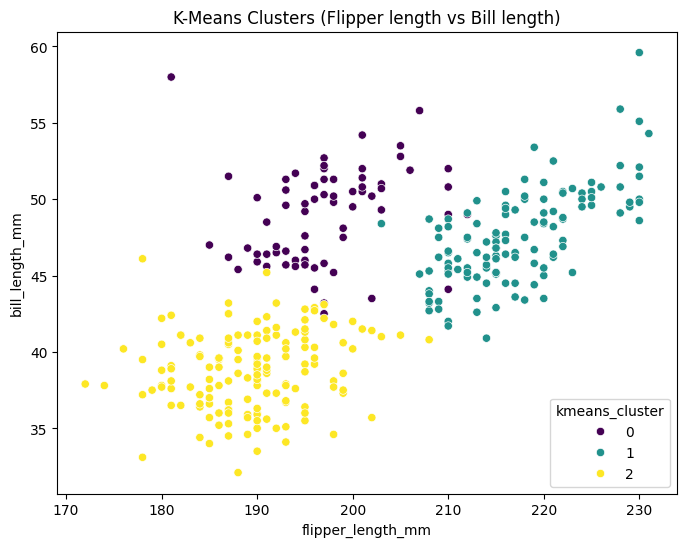

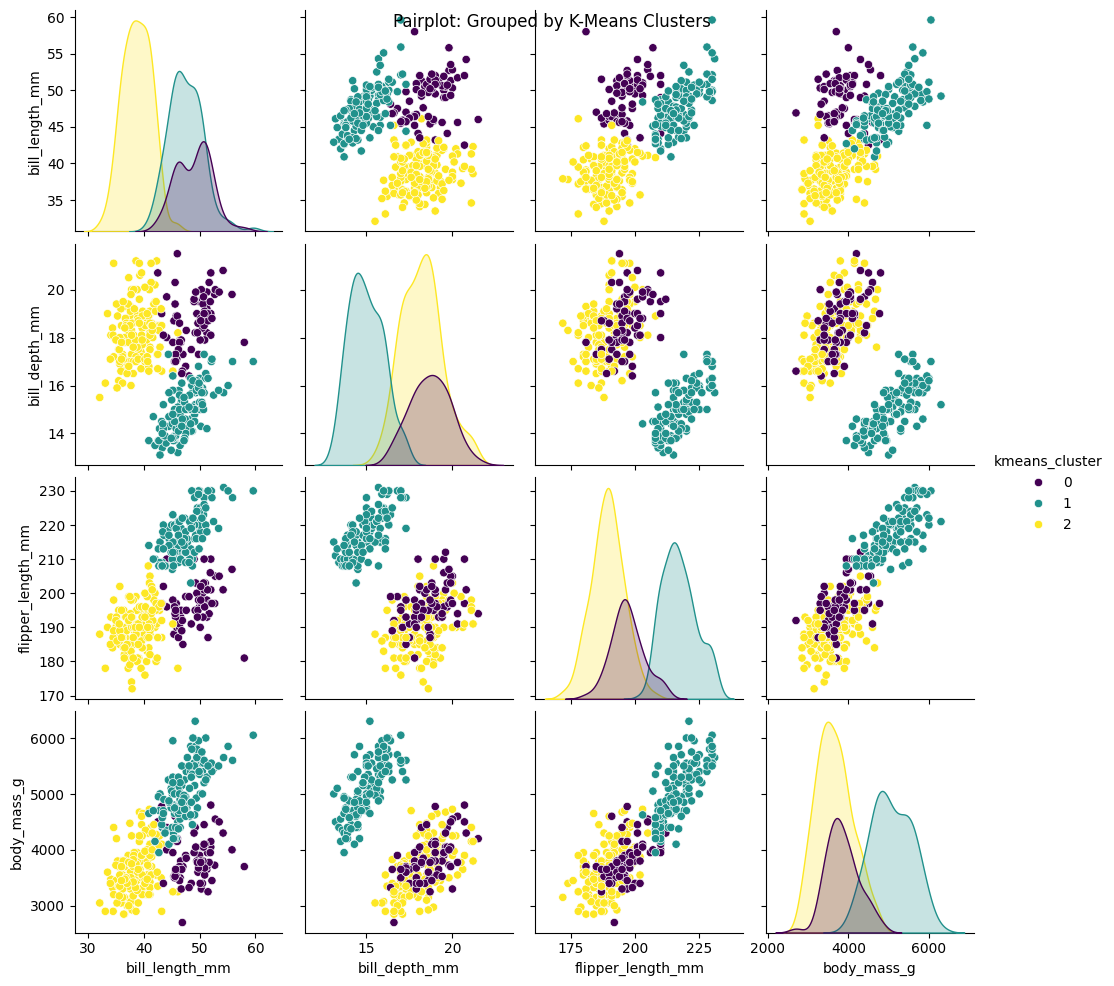

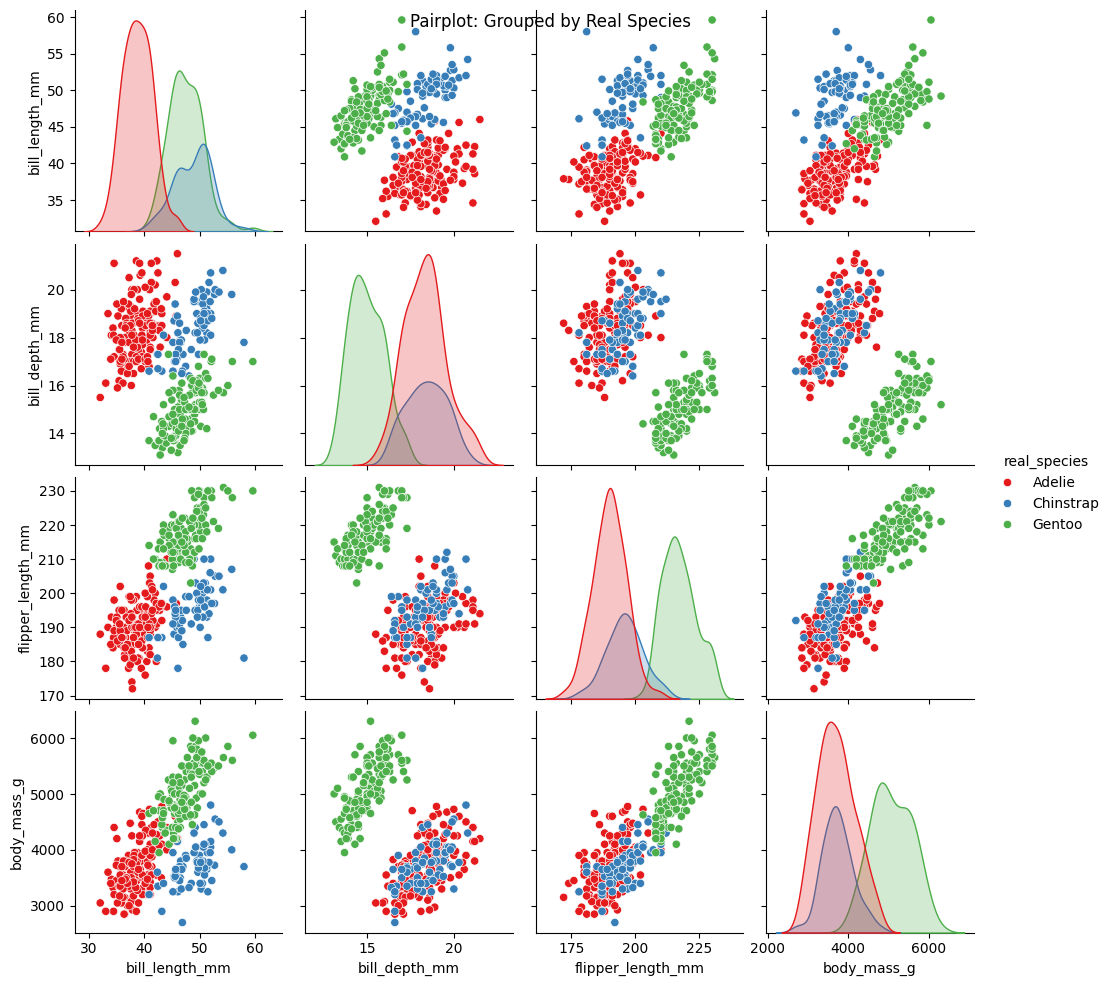

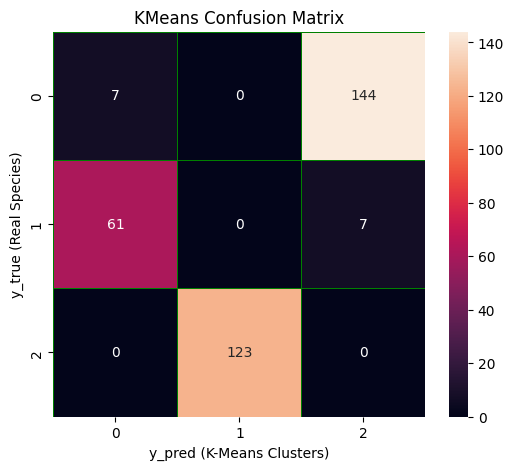


Adjusted Rand Score: 0.893439770351491


In [12]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean
penguins_clean = None

# SELECT JUST 4 NEEDED COL FROM DATASET
penguins_num = penguins[num_cols]

# CHECK HOW MANY MISSING VALUES THERE ARE
print("Missing values BEFORE cleaning:")
print(penguins_num.isna().sum())

# REMOVE EVERY ROW WITH MISSING VALUES
penguins_clean = penguins_num.dropna()

# CHECK THE DATAFRAME IS NOW CLEAN
print("\nMissing values AFTER cleaning:")
print(penguins_clean.isna().sum())

# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
penguins_scaled_df = None

# Initialize the StandardScaler
scaler = StandardScaler()

# Fit the scaler to the clean data and transform it
penguins_scaled_matrix = scaler.fit_transform(penguins_clean)

# Convert the resulting numpy array back into a pandas DataFrame
penguins_scaled_df = pd.DataFrame(penguins_scaled_matrix, columns=num_cols)

# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
kmeans_labels = None

# Initialize KMeans asking for 3 clusters (since we have 3 penguin species)
kmeans = KMeans(n_clusters=3)

# Fit the model and extract the final result of the algorithm so our predicted cluster labels (0, 1, or 2)
kmeans_labels = kmeans.fit_predict(penguins_scaled_df)

# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)

# Create a copy of the unscaled dataframe for the next step
df_plot = penguins_clean.copy()

# Add the predicted K-Means labels as a new column
df_plot['kmeans_cluster'] = kmeans_labels

# Extract the real species names (ground truth) from the original dataframe (penguins) using loc function
# but selecting only the rows of clean dataset. Then we add it to df_plot for comparison
df_plot['real_species'] = penguins.loc[penguins_clean.index, 'species']

# Plot 1: Scatterplot (Flipper vs Bill length) colored by K-Means cluster
plt.figure(figsize=(8,6))
sns.scatterplot(x='flipper_length_mm', y='bill_length_mm', hue='kmeans_cluster', data=df_plot, palette='viridis')
plt.title("K-Means Clusters (Flipper length vs Bill length)")
plt.show()

# Plot 2: Pairplot colored by predicted K-Means cluster
# We drop the 'real_species' column so it doesn't interfere with the pairplot
sns.pairplot(df_plot.drop('real_species', axis=1), hue='kmeans_cluster', palette='viridis')
plt.suptitle("Pairplot: Grouped by K-Means Clusters")
plt.show()

# Plot 3: Pairplot colored by actual biological species
# We drop the 'kmeans_cluster' column for this comparison
sns.pairplot(df_plot.drop('kmeans_cluster', axis=1), hue='real_species', palette='Set1')
plt.suptitle("Pairplot: Grouped by Real Species")
plt.show()


# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'

# Import the tool to translate text labels (grounf truth) into numbers
from sklearn.preprocessing import LabelEncoder

# Initialize the LabelEncoder
le = LabelEncoder()

# Transform the true species column (text) into numeric labels (0, 1, 2) to match K-Means output
true_labels_numeric = le.fit_transform(df_plot['real_species'])

# Compute the confusion matrix comparing the numeric ground truth against K-Means clusters
cm = confusion_matrix(true_labels_numeric, kmeans_labels)

# Set up a single plot figure (1 row, 1 column)
fig, ax = plt.subplots(1, 1, figsize=(6, 5))

# Plot the confusion matrix as a heatmap using:
# annot=True: shows the numbers inside the squares
# fmt=".0f": formats the numbers as integers (no decimal points)
# linewidths/linecolor: draws a green grid between squares
sns.heatmap(cm, annot=True, linewidths=0.5, linecolor="green", fmt=".0f", ax=ax)

# Add labels to the axes
plt.xlabel("y_pred (K-Means Clusters)")
plt.ylabel("y_true (Real Species)")
plt.title('KMeans Confusion Matrix')

# Display the plot
plt.show()

# Compute the Adjusted Rand Score to evaluate the clustering performance mathematically
ars = adjusted_rand_score(true_labels_numeric, kmeans_labels)
print(f"\nAdjusted Rand Score: {ars}")


# f) YOUR CODE HERE (as a comment or markdown cell): interpretation



## **f) CONFUSION MATRIX INTERPRETATION**
Because K-Means is an unsupervised machine learning algorithm, it does not know the true biological names of the species during training. It simply identifies three distinct geometric groups in the data and arbitrarily assigns them labels (0, 1, and 2).
Therefore, true positives will not necessarily align on the main diagonal. Instead, we must identify the highest value in each row to see how the algorithm mapped its arbitrary clusters to the real species:

*  Species 0 (Adelie) was mapped to Cluster 2 (144 correct assignments).
*  Species 1 (Chinstrap) was mapped to Cluster 0 (61 correct assignments).
*  Species 2 (Gentoo) was mapped to Cluster 1 (123 correct assignments).

Overall, K-Means recovers the three species well. The matrix shows that Species 2 (Gentoo) is perfectly isolated with zero errors (123 out of 123). The majority of the other two species are also accurately grouped into their respective primary clusters.
As result, the algorithm achieves a high Adjusted Rand Score.

In particular, Species 0 (Adelie) and Species 1 (Chinstrap) experience slight confusion. The matrix reveals exactly 14 misclassifications: 7 Adelie penguins were incorrectly placed into the Chinstrap cluster, and 7 Chinstrap penguins were placed into the Adelie cluster. This occurs because Adelie and Chinstrap penguins share very similar physical dimensions (such as flipper length and weight), whereas Gentoo penguins are distinctly larger and therefore easily separated by the algorithm.

Finally, normalization was absolutely critical. K-Means forms clusters by calculating the Euclidean distance between data points. If we had used the raw values, the body_mass_g feature would have completely dominated the distance equations. The algorithm would have ignored the other measurements and grouped the penguins almost entirely by weight.

---------------------------------------------------------

NOTE ON THE CODE:

**Libraries Overview:**

*pandas*: Used for data manipulation and handling missing values.
*matplotlib & seaborn*: Used for data visualization (creating scatterplots and pairplots).
*sklearn*: The core machine learning library. We use KMeans for the algorithm, StandardScaler for preprocessing, and confusion_matrix / adjusted_rand_score for mathematical evaluation.

**Step B: Normalization**

Variables like body_mass_g (thousands) and bill_length_mm (tens) operate on vastly different scales. Since K-Means relies on distance, larger magnitude features would unfairly dominate the clustering process.
We applied StandardScaler to standardize all features to a mean of 0 and a standard deviation of 1, giving them equal weight.

**Step C & D: Modeling and Visualization**

We initialized the model with n_clusters=3, matching the known number of penguin species, and extracted the labels via .fit_predict().

NOTE FOR EXTRACT THE GROUND TRUTH:
Since the initial dropna() operation removed rows with missing values, the index of our clean dataset no longer perfectly matches the original one. If we just copied the column directly, Pandas would misalign the labels. So I decided to use loc function. By passing penguins_clean.index inside .loc, we force Pandas to extract the exact 'species' labels only for the surviving rows. This guarantees a perfect row-by-row alignment between our K-Means predictions and the real biological species before computing the confusion matrix.

NOTE FOR Pairplot Grid:

Diagonals (Density Curves): Instead of crossing two variables, the diagonal plots show the distribution of a single feature. The peaks (or "mountains") indicate where the data values are most concentrated for each species, helping us see if a species is naturally larger or smaller in that specific measurement.

Off-diagonals (Scatterplots): These grids cross two different variables against each other (X vs Y). They visualize the relationship and correlation between features, allowing us to see exactly where the penguin species form distinct separated clusters and where they overlap in 2D space.



---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

Are there missing values? False
5.656854249492381
5.656854249492381


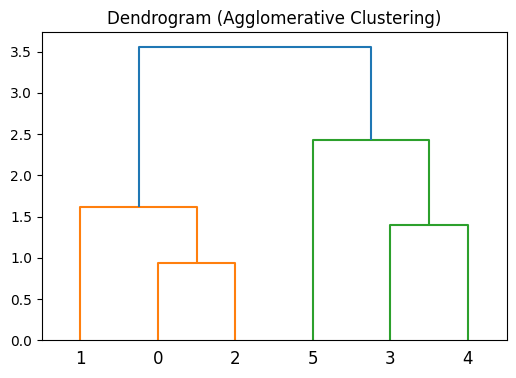


Agglomerative Labels: [1 1 1 0 0 0]
K-Means Labels: [0 0 0 1 1 1]


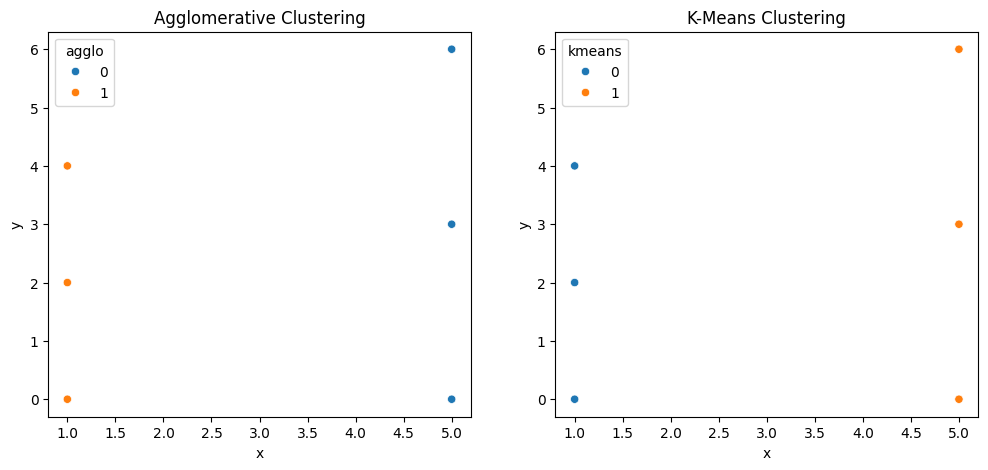


Agglomerative cluster sizes: {np.int64(1): 3, np.int64(0): 3}
K-Means cluster sizes: {np.int32(0): 3, np.int32(1): 3}


In [22]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any() which returns True or False
print("Are there missing values?", np.isnan(X).any())

# b) YOUR CODE HERE: normalize X with StandardScaler
X_scaled = None

# Initialize the scaler and normalize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)

def euclidean_distance(p1, p2):

  # Start with a total sum of 0
    sum_squared = 0

    # Loop through each coordinate of the points with len(p1)=2 (x and y)
    for i in range(len(p1)):

        # Subtract the coordinates, square the result, and add to the sum
        sum_squared += (p1[i] - p2[i]) ** 2

    # Return the square root of the total sum (which is power of 0.5)
    return sum_squared ** 0.5

# test it
print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))

# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram
agglo_labels = None

# Apply Agglomerative Clustering asking for 2 clusters
agglo = AgglomerativeClustering(n_clusters=2)
agglo_labels = agglo.fit_predict(X_scaled)

# Plot the dendrogram
plt.figure(figsize=(6, 4))

# Calculate the linkage matrix required for the dendrogram
Z = linkage(X_scaled, method='ward')
dendrogram(Z)
plt.title("Dendrogram (Agglomerative Clustering)")
plt.show()

# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled
kmeans_labels = None

# Apply KMeans asking for 2 clusters (random_state ensures the same result every time)
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot
print("\nAgglomerative Labels:", agglo_labels)
print("K-Means Labels:", kmeans_labels)

# Convert the original array X into a pandas DataFrame (required for Seaborn hue mapping)
df_X = pd.DataFrame(X, columns=['x', 'y'])

# Add the cluster labels to our DataFrame
df_X['agglo'] = agglo_labels
df_X['kmeans'] = kmeans_labels

# Create a wider figure (12, 5) to fit two plots side-by-side comfortably
fig = plt.figure(figsize=(12, 5))

# Create the left subplot (1 row, 2 columns, position 1)
plt.subplot(121)
sns.scatterplot(x='x', y='y', hue='agglo', data=df_X)
plt.title("Agglomerative Clustering")

# Create the right subplot (1 row, 2 columns, position 2)
plt.subplot(122)
sns.scatterplot(x='x', y='y', hue='kmeans', data=df_X)
plt.title("K-Means Clustering")

plt.show()

# g) YOUR CODE HERE: cluster_sizes function using a dictionary

def cluster_sizes(labels):
    sizes = {}
    for label in labels:
        if label in sizes:
            sizes[label] += 1
        else:
            sizes[label] = 1
    return sizes

print("\nAgglomerative cluster sizes:", cluster_sizes(agglo_labels))
print("K-Means cluster sizes:", cluster_sizes(kmeans_labels))


---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

Missing values before cleaning:
 carat    0
depth    0
table    0
price    0
dtype: int64
Missing values after cleaning:
 carat    0
depth    0
table    0
price    0
dtype: int64


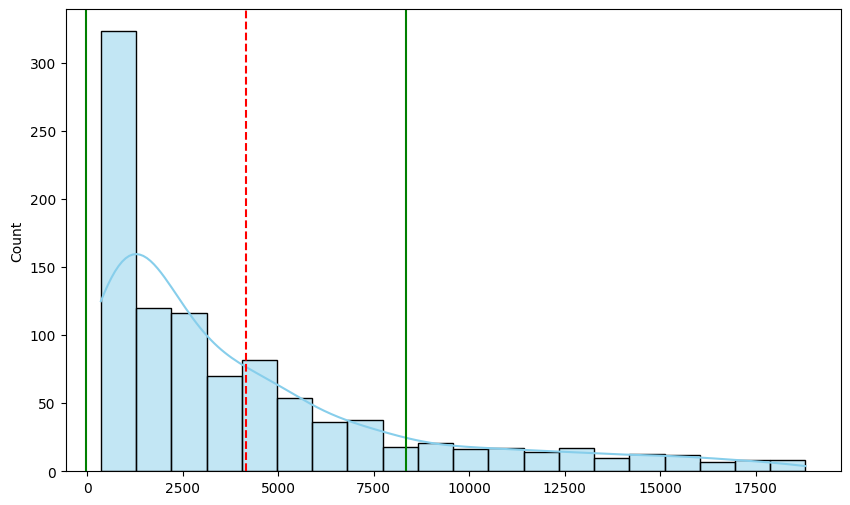

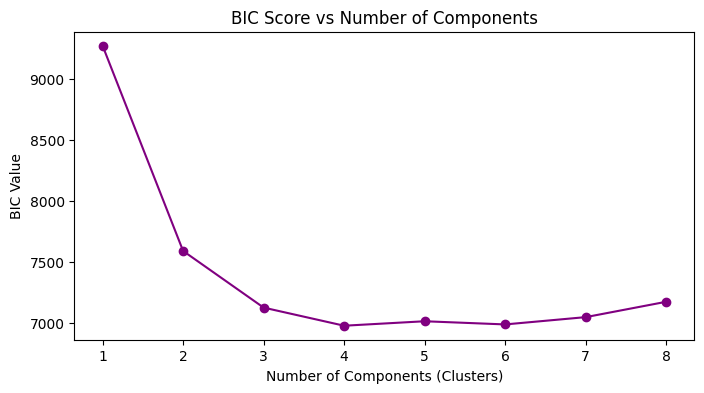

Optimal number of components (min BIC): 4


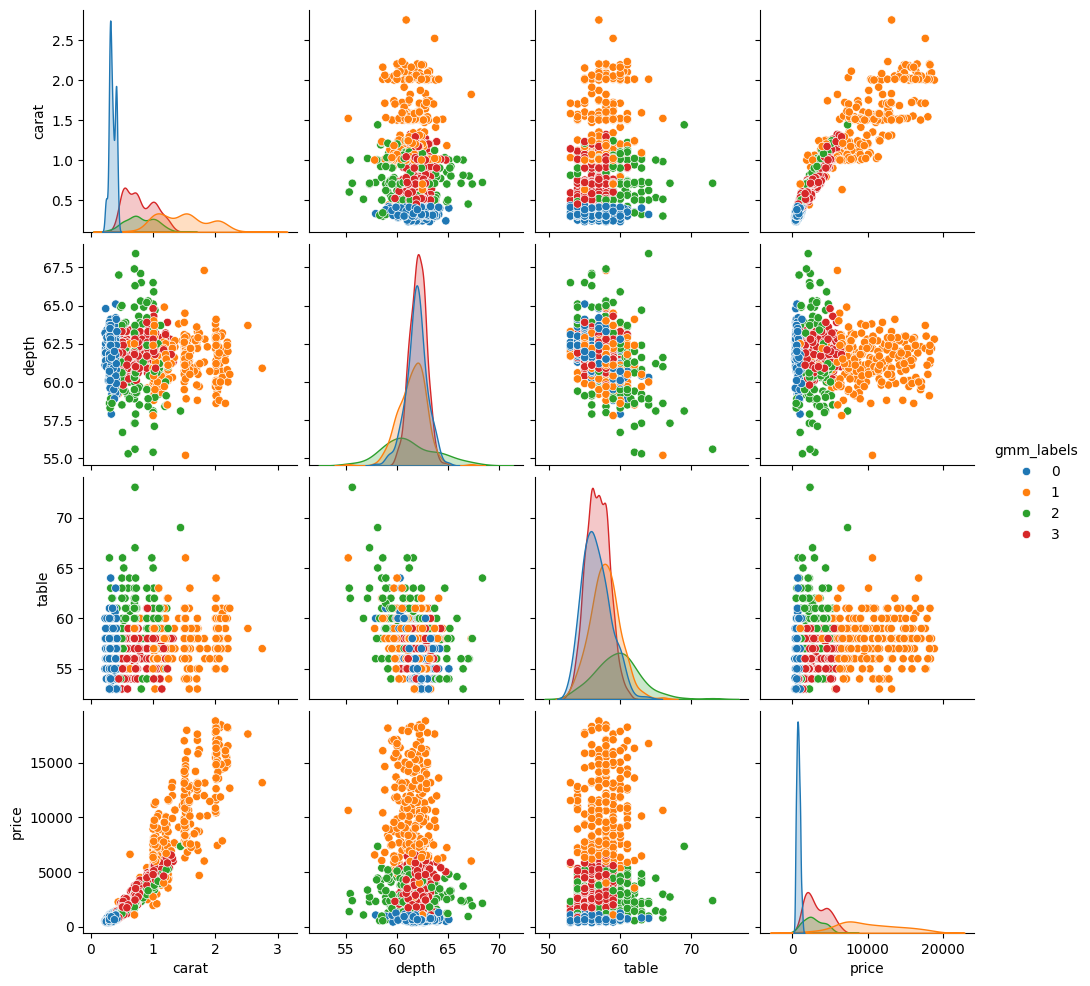

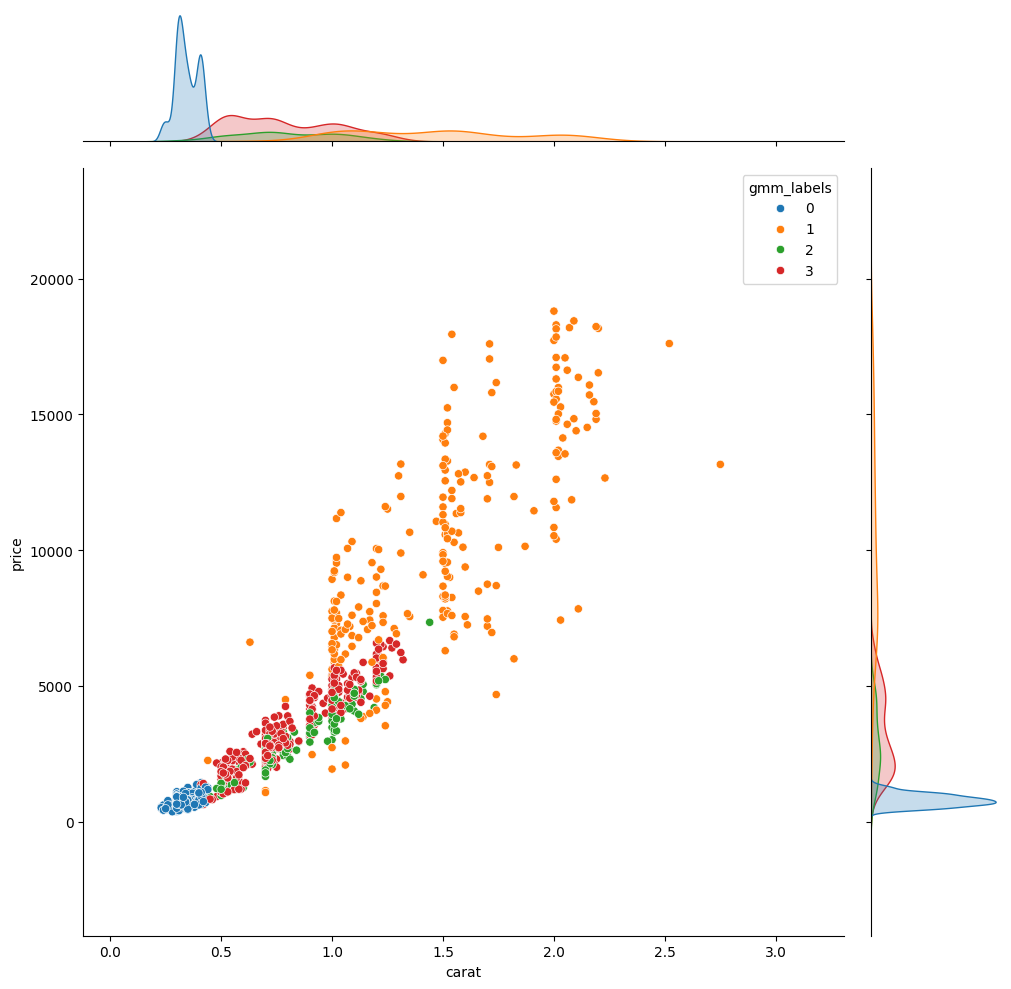

In [10]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
diamonds_num = None

# Select only the numeric columns (the [[]] indicates that diamonds_num is already a dataframe, it's not necessary pd.DataFrame(...))
diamonds_num = diamonds[['carat', 'depth', 'table', 'price']]

# Check for missing values before cleaning
print("Missing values before cleaning:\n", diamonds_num.isna().sum())

# Drop rows with NaN values and confirm data is clean
diamonds_num = diamonds_num.dropna()
print("Missing values after cleaning:\n", diamonds_num.isna().sum())

# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines

# Calculate mean and standard deviation for the price
media_price = diamonds_num['price'].mean()
std_price = diamonds_num['price'].std()

# Create the figure
fig = plt.figure(figsize=(10, 6))

# Use histplot (with kde=True)
ax = sns.histplot(diamonds_num["price"].values, bins=20, kde=True, color='skyblue')

# Add vertical lines:

# Red dashed line for the mean
plt.axvline(media_price, color="r", linestyle="--")

# Green solid lines for mean +/- standard deviation
plt.axvline(media_price + std_price, color="g", linestyle="-")
plt.axvline(media_price - std_price, color="g", linestyle="-")

plt.show()

# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
diamonds_scaled = None

# Initialize StandardScaler to give all features equal weight
scaler = StandardScaler()
diamonds_scaled = scaler.fit_transform(diamonds_num)

# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)

for n in n_components_range:

    # Initialize GMM for each component count (with random_state for reproducibility)
    gmm = mixture.GaussianMixture(n_components=n, random_state=42)
    gmm.fit(diamonds_scaled)

    # Append the Bayesian Information Criterion (BIC) score
    bic.append(gmm.bic(diamonds_scaled))

# Plot BIC score vs number of components
plt.figure(figsize=(8, 4))
plt.plot(n_components_range, bic, marker='o', color='purple')
plt.title("BIC Score vs Number of Components")
plt.xlabel("Number of Components (Clusters)")
plt.ylabel("BIC Value")
plt.show()

# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM
best_n = None
gmm_labels = None

# Find the index of the lowest BIC value
best_index = np.argmin(bic)
best_n = n_components_range[best_index]
print(f"Optimal number of components (min BIC): {best_n}")

# Fit the final GMM model using the optimal number of components
final_gmm = mixture.GaussianMixture(n_components=best_n, random_state=42)
gmm_labels = final_gmm.fit_predict(diamonds_scaled)

# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)

diamonds_num['gmm_labels'] = gmm_labels

# Create a pairplot colored by the GMM cluster labels (hue)
sns.pairplot(diamonds_num, hue='gmm_labels',palette='tab10')
plt.show()

# Create a jointplot focusing on carat vs price
sns.jointplot(x='carat', y='price', data=diamonds_num, hue='gmm_labels', height=10,palette='tab10')
plt.show()

# g) YOUR CODE HERE (as a comment or markdown cell): interpretation


## g) PLOT INTERPRETATION

The optimal number of components (4) chosen automatically by the BIC algorithm seems reasonable visually even though it is actually not obvious to the naked eye that there should be exactly 4 clusters. If we only look at the 2D plot of 'carat' versus 'price', we might only notice 2 or 3 main groups.

This is the reason why we rely on BIC which gives us an objective, mathematical criterion.
Firstly, the algorithm works in 4 dimensions simultaneously (carat, depth, table, and price). Boundaries that look overlapping or mixed to us in a flat 2D plot are actually well-separated clusters in a 4D space.
Secondly, the BIC score prevents the model from overfitting.

Moreover, normalizing the data is extremely important here. The 'price' variable goes up to thousands of dollars, while 'depth' and 'table' are small percentages (around 60). If we don't scale the data, the algorithm will only focus on 'price' because its numbers are huge, completely ignoring the other features.